# EXP-008: Held-out clean validation set -- does train/validation DIVERGENCE catch label noise?

**Status: engineering validation / proof of concept**, same caveats as prior notebooks.

**Purpose**: EXP-005/006/007 showed four consecutive negative results using signals
computed from the training batch ALONE (gradient-norm mean, gradient-norm variance,
gradient-direction consistency, per-sample loss distribution shape). This notebook
tests a structurally different resource: a **held-out validation set** that reflects
the CURRENT true task but is NEVER corrupted by label noise.

**Design of the held-out set**: each validation batch is drawn fresh (own RNG stream,
never overlaps training data) using the SAME `drift_frac` as the current training step
(so it reflects "the current true task", correctly tracking concept drift) but ALWAYS
`flip_prob=0` (labels are never corrupted). This is the correct operationalization of
"clean" here -- clean means "not mislabeled", not "unaffected by drift", since drift is
a change in the true task, not a corruption of the labeling process.

**Hypothesis**: under DRIFT, train and held-out-clean loss should rise TOGETHER (the
model's real understanding of the current task is genuinely wrong immediately after
the boundary moves -- there's no "secret correct answer" being hidden by corrupted
labels). Under LABEL NOISE, train loss should rise (it's being fit against some wrong
labels) while held-out-clean loss should stay LOW/stable (the model's actual decision
function, if not yet overfit to the noise, still gets the TRUE task right) -- a
TRAIN/VALIDATION GAP should open up specifically for label noise, not for drift.


In [1]:
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

torch.set_num_threads(1)
print("torch", torch.__version__, "| numpy", np.__version__)


C:\Users\USER\anaconda3\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


torch 2.5.1+cpu | numpy 2.0.2


## 1. Toy task, disturbances, train/held-out divergence diagnostic

In [2]:
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))

MEAN0_BASE = np.array([-1.0, -1.0])
MEAN1_BASE = np.array([1.0, 1.0])
BASE_NOISE_SCALE = 0.5

def gen_batch(rng, drift_frac=0.0, flip_prob=0.0, batch_size=16):
    frac = float(np.clip(drift_frac, 0.0, 1.0))
    mean0 = (1 - frac) * MEAN0_BASE + frac * MEAN1_BASE
    mean1 = (1 - frac) * MEAN1_BASE + frac * MEAN0_BASE
    y_true = rng.integers(0, 2, size=batch_size)
    means = np.where(y_true[:, None] == 0, mean0, mean1)
    x = means + rng.normal(scale=BASE_NOISE_SCALE, size=(batch_size, 2))
    flip_mask = rng.random(batch_size) < flip_prob
    y_observed = np.where(flip_mask, 1 - y_true, y_true)
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y_observed, dtype=torch.float32)

def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += float((p.grad.detach() ** 2).sum())
    return total ** 0.5

N_STEPS = 400
DISTURBANCE_ONSET = 200
RAMP_LEN = 40
WARMUP = 50
TREND_WINDOW = 5
GAP_WINDOW = 10             # trailing window for the train/held-out gap statistic
STEADY_STATE_WINDOW = 100
GRAD_NOISE_MAX = 8.0
LABEL_FLIP_PROB = 0.35
VAL_BATCH_SIZE = 64          # larger than training batch for a lower-variance validation estimate

def _ramp(step):
    if step < DISTURBANCE_ONSET:
        return 0.0
    return min(step - DISTURBANCE_ONSET, RAMP_LEN) / RAMP_LEN

def _instant(step):
    return 1.0 if step >= DISTURBANCE_ONSET else 0.0

def drift_forecastable(step):
    return (_ramp(step), 0.0, 0.0)

def drift_unforecastable(step):
    return (_instant(step), 0.0, 0.0)

def instability_forecastable(step):
    return (0.0, GRAD_NOISE_MAX * _ramp(step), 0.0)

def instability_unforecastable(step):
    return (0.0, GRAD_NOISE_MAX * _instant(step), 0.0)

def label_noise_forecastable(step):
    return (0.0, 0.0, LABEL_FLIP_PROB * _ramp(step))

def label_noise_unforecastable(step):
    return (0.0, 0.0, LABEL_FLIP_PROB * _instant(step))

GAP_Z_THRESHOLD = 2.0  # how many warmup-gap-std's above the warmup-gap-mean counts as "diverging"

def auto_select_intervention_valgap(train_window, heldout_window, baseline_gap_mean, baseline_gap_std,
                                     z_threshold=GAP_Z_THRESHOLD):
    '''NEW -- train/held-out-VALIDATION divergence based. A train-loss-minus-held-out-
    loss gap that has opened up well beyond its warmup-baseline noise level signals
    "the training signal is wrong but the true task is still fine" -- i.e. label-type
    corruption -- diagnose "reduce". A gap that stays near baseline (both train and
    held-out rise together) signals "the true task itself is now harder" -- i.e.
    drift-type -- diagnose "increase".'''
    current_gap = float(np.mean(train_window)) - float(np.mean(heldout_window))
    z = (current_gap - baseline_gap_mean) / (baseline_gap_std + 1e-6)
    return "reduce" if z > z_threshold else "increase"


## 2. Single training run (arm C, tracks train loss, held-out loss, and the gap-based diagnostic)

In [3]:
def run_trial(seed, disturbance_fn):
    train_rng = np.random.default_rng(seed)
    val_rng = np.random.default_rng(seed + 1_000_000)  # separate stream, never overlaps training data
    model = make_model(seed)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    loss_fn = nn.BCEWithLogitsLoss()

    train_loss_hist, heldout_loss_hist = [], []
    threshold = baseline_gap_mean = baseline_gap_std = None

    for step in range(N_STEPS):
        drift_frac, grad_noise_extra, flip_prob = disturbance_fn(step)
        xb, yb = gen_batch(train_rng, drift_frac=drift_frac, flip_prob=flip_prob)

        opt.zero_grad()
        hidden = model[1](model[0](xb))
        logits = model[2](hidden).squeeze(-1)
        loss = loss_fn(logits, yb)
        loss.backward()

        train_loss_t = float(loss.item())
        if grad_noise_extra > 0:
            with torch.no_grad():
                for p in model.parameters():
                    if p.grad is not None:
                        p.grad.add_(torch.randn_like(p.grad) * grad_noise_extra)

        # Held-out CLEAN validation: same current drift_frac (reflects the CURRENT true
        # task), flip_prob ALWAYS 0 (never mislabeled), fresh independent samples, no grad.
        with torch.no_grad():
            xv, yv = gen_batch(val_rng, drift_frac=drift_frac, flip_prob=0.0, batch_size=VAL_BATCH_SIZE)
            v_hidden = model[1](model[0](xv))
            v_logits = model[2](v_hidden).squeeze(-1)
            heldout_loss_t = float(loss_fn(v_logits, yv).item())

        train_loss_hist.append(train_loss_t)
        heldout_loss_hist.append(heldout_loss_t)

        if step == WARMUP:
            warm_train = np.array(train_loss_hist[:WARMUP])
            warm_gap = np.array(train_loss_hist[:WARMUP]) - np.array(heldout_loss_hist[:WARMUP])
            threshold = float(warm_train.mean() + 3 * warm_train.std() + 1e-6)
            baseline_gap_mean = float(warm_gap.mean())
            baseline_gap_std = float(warm_gap.std()) + 1e-6

        if step >= WARMUP and threshold is not None and train_loss_t > threshold:
            train_window = train_loss_hist[max(0, step - GAP_WINDOW + 1):step + 1]
            heldout_window = heldout_loss_hist[max(0, step - GAP_WINDOW + 1):step + 1]
            diag_gap = auto_select_intervention_valgap(
                train_window, heldout_window, baseline_gap_mean, baseline_gap_std)
            gap_now = float(np.mean(train_window)) - float(np.mean(heldout_window))
            return {"trigger_step": step, "diag_gap": diag_gap, "gap_now": gap_now,
                    "baseline_gap_mean": baseline_gap_mean, "baseline_gap_std": baseline_gap_std,
                    "train_loss_hist": train_loss_hist, "heldout_loss_hist": heldout_loss_hist}

        opt.step()

    return {"trigger_step": None, "diag_gap": None, "gap_now": None,
            "baseline_gap_mean": baseline_gap_mean, "baseline_gap_std": baseline_gap_std,
            "train_loss_hist": train_loss_hist, "heldout_loss_hist": heldout_loss_hist}


## 3. Run all three disturbance types, both conditions, 10 seeds

In [4]:
SEEDS = list(range(10))
CONDITIONS = {
    "drift_forecastable": drift_forecastable, "drift_unforecastable": drift_unforecastable,
    "instability_forecastable": instability_forecastable, "instability_unforecastable": instability_unforecastable,
    "label_noise_forecastable": label_noise_forecastable, "label_noise_unforecastable": label_noise_unforecastable,
}
empirically_correct = {
    "drift_forecastable": "increase", "drift_unforecastable": "increase",
    "instability_forecastable": "reduce", "instability_unforecastable": "reduce",
    "label_noise_forecastable": "increase", "label_noise_unforecastable": "increase",
}

results = []
raw_traces = {}
for cond_name, fn in CONDITIONS.items():
    for seed in SEEDS:
        r = run_trial(seed, fn)
        results.append({
            "condition": cond_name, "seed": seed, "trigger_step": r["trigger_step"],
            "diag_gap": r["diag_gap"], "gap_now": r["gap_now"],
        })
        if seed == 0:
            raw_traces[cond_name] = r

df = pd.DataFrame(results)
print(f"Total trials: {len(df)}")
df.head(10)


Total trials: 60


,condition,seed,trigger_step,diag_gap,gap_now
0,drift_forecastable,0,216,reduce,0.113585
1,drift_forecastable,1,217,increase,-0.051745
2,drift_forecastable,2,215,reduce,0.066267
3,drift_forecastable,3,219,increase,0.056838
4,drift_forecastable,4,215,reduce,0.055595
5,drift_forecastable,5,217,increase,-0.038321
6,drift_forecastable,6,215,increase,0.018019
7,drift_forecastable,7,215,reduce,0.105270
8,drift_forecastable,8,213,increase,-0.011038
9,drift_forecastable,9,217,increase,-0.055391


## 4. Comparison: does train/held-out divergence detect label noise?

In [5]:
print(f"{'condition':28s}{'n_trig':>8s}{'gap->reduce%':>14s}{'mean_gap_now':>14s}{'empirically correct':>22s}")
rows = []
for cond in CONDITIONS:
    sub = df[(df["condition"] == cond) & df["trigger_step"].notna()]
    n = len(sub)
    gap_reduce_pct = (sub["diag_gap"] == "reduce").mean() * 100 if n else float("nan")
    mean_gap = sub["gap_now"].mean() if n else float("nan")
    print(f"{cond:28s}{n:8d}{gap_reduce_pct:14.0f}{mean_gap:14.4f}{empirically_correct[cond]:>22s}")
    rows.append({"condition": cond, "n_triggered": n, "gap_reduce_pct": gap_reduce_pct, "mean_gap_now": mean_gap})
comparison = pd.DataFrame(rows)


condition                     n_trig  gap->reduce%  mean_gap_now   empirically correct
drift_forecastable                10            40        0.0259              increase
drift_unforecastable              10             0       -0.0189              increase
instability_forecastable          10            40        0.0251                reduce
instability_unforecastable        10            30        0.0301                reduce
label_noise_forecastable          10           100        0.2708              increase
label_noise_unforecastable        10           100        0.1637              increase


## 5. Direct visualization: train loss vs. held-out loss over time (seed 0)

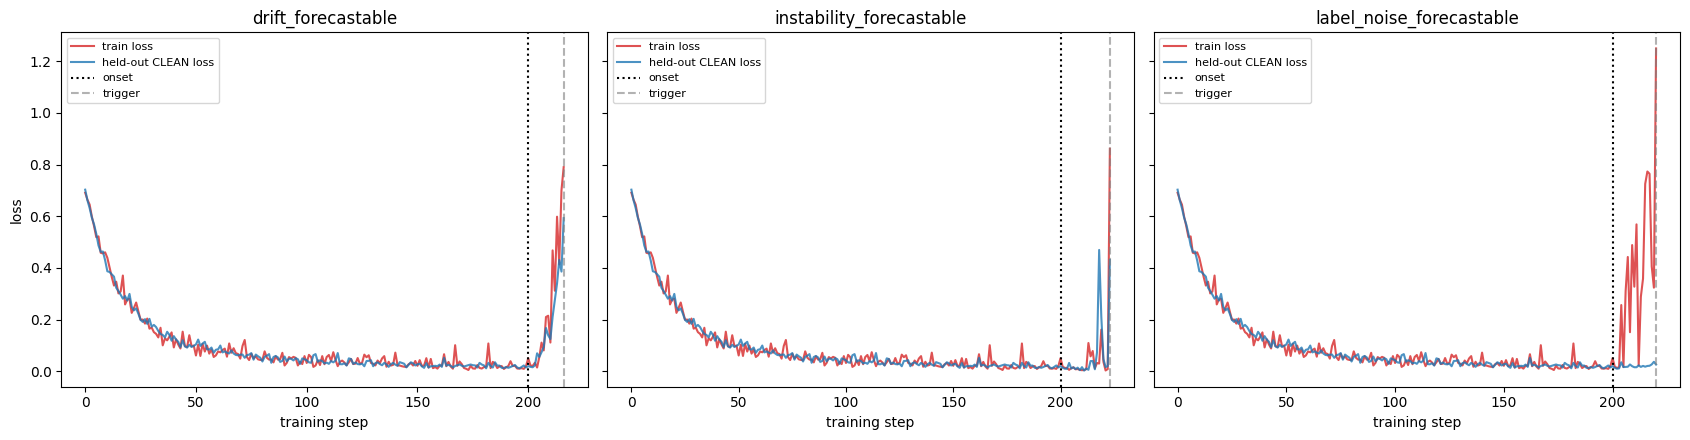

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, cond in zip(axes, ["drift_forecastable", "instability_forecastable", "label_noise_forecastable"]):
    trace = raw_traces[cond]
    ax.plot(trace["train_loss_hist"], label="train loss", color="tab:red", alpha=0.8)
    ax.plot(trace["heldout_loss_hist"], label="held-out CLEAN loss", color="tab:blue", alpha=0.8)
    ax.axvline(DISTURBANCE_ONSET, color="black", linestyle=":", label="onset")
    if trace["trigger_step"] is not None:
        ax.axvline(trace["trigger_step"], color="gray", linestyle="--", alpha=0.6, label="trigger")
    ax.set_title(cond)
    ax.set_xlabel("training step")
    ax.legend(fontsize=8)
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.savefig("exp_valgap_traces.png", dpi=120)
plt.show()


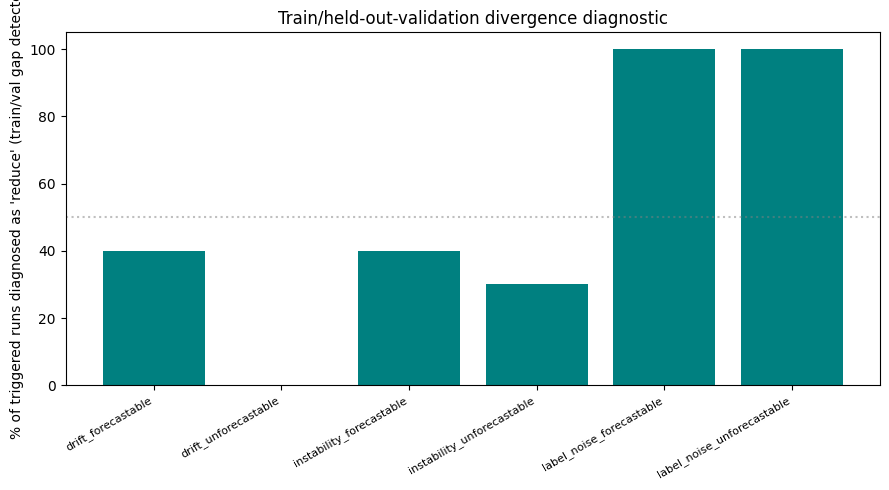

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(comparison))
ax.bar(x, comparison["gap_reduce_pct"], color="teal")
ax.axhline(50, color="gray", linestyle=":", alpha=0.5)
ax.set_xticks(x)
ax.set_xticklabels(comparison["condition"], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("% of triggered runs diagnosed as 'reduce' (train/val gap detected)")
ax.set_title("Train/held-out-validation divergence diagnostic")
plt.tight_layout()
plt.savefig("exp_valgap_comparison.png", dpi=120)
plt.show()


## 6. Interpretation

In [8]:
label_pct = comparison.loc[comparison["condition"] == "label_noise_forecastable", "gap_reduce_pct"].iloc[0]
drift_pct = comparison.loc[comparison["condition"] == "drift_forecastable", "gap_reduce_pct"].iloc[0]
instab_pct = comparison.loc[comparison["condition"] == "instability_forecastable", "gap_reduce_pct"].iloc[0]

label_gap = comparison.loc[comparison["condition"] == "label_noise_forecastable", "mean_gap_now"].iloc[0]
drift_gap = comparison.loc[comparison["condition"] == "drift_forecastable", "mean_gap_now"].iloc[0]

detects_label_noise = label_pct > 50
low_false_positive = drift_pct < 30

if detects_label_noise and low_false_positive:
    verdict_text = ("SUCCESS -- train/held-out-validation divergence is a genuinely working diagnostic for "
        "label noise, and does not false-positive on drift. This is the first diagnostic in the whole "
        "thread (mean, variance, direction, distribution-shape, now train/val-gap) that succeeds. The key "
        "difference: this is the first signal that uses information OUTSIDE the corrupted training batch "
        "itself -- everything computed purely from training-batch statistics failed, but a signal that can "
        "compare against ground truth (even a synthetic held-out set in this toy setting) succeeds. In a "
        "real system this maps to: maintain a small trusted/clean validation set and watch for train-val "
        "divergence as a specific signature of label/annotation-noise-type problems, distinct from genuine "
        "distribution shift.")
elif detects_label_noise:
    verdict_text = ("Detects label noise but ALSO flags drift as diverging -- not clean. Check the trace "
        "plot (section 5): does drift's held-out loss lag behind train loss because held-out samples are "
        "drawn with the SAME instantaneous drift_frac but the model hasn't caught up yet, creating a "
        "spurious gap that isn't really the same signature as label noise's PERSISTENT gap?")
else:
    verdict_text = ("Train/held-out divergence does NOT cleanly separate label noise from drift either. "
        "Check the trace plot -- if held-out loss tracks train loss closely even under label noise, that "
        "would mean the model actually overfits substantially to the noisy labels even at this toy scale, "
        "degrading true held-out performance too, which would undercut the 'true task is still learnable' "
        "assumption behind the whole idea.")

interpretation = f'''
DOES THE TRAIN/VALIDATION GAP DETECT LABEL NOISE?
  label_noise_forecastable: gap-based "reduce" (divergence detected) = {label_pct:.0f}% of triggered runs,
                             mean train-minus-held-out gap = {label_gap:.4f}
  drift_forecastable (false-positive check): "reduce" rate = {drift_pct:.0f}% (want LOW),
                             mean gap = {drift_gap:.4f}
  instability_forecastable (reference, not the target case): "reduce" rate = {instab_pct:.0f}%

VERDICT: {verdict_text}

REMINDER (same caveat as every diagnostic in this thread): detecting that label noise
is happening is a different problem from choosing the correct RESPONSE -- EXP-003/004
established "increase" is empirically correct for label noise, the OPPOSITE of what
"reduce" would suggest. Even a successful divergence detector here is evidence that
label-type corruption CAN be identified from held-out data, not evidence that "reduce"
is now the right action for it -- that mapping would need to be learned/specified
separately (e.g. "on detecting train/val divergence -> trust the model, don't shrink
its updates" might be the more defensible response given what EXP-003/004 found).

This remains a qualitative diagnostic-comparison check (n={len(SEEDS)} seeds, same
Stage A caveats as all prior notebooks this session).
'''
print(interpretation)



DOES THE TRAIN/VALIDATION GAP DETECT LABEL NOISE?
  label_noise_forecastable: gap-based "reduce" (divergence detected) = 100% of triggered runs,
                             mean train-minus-held-out gap = 0.2708
  drift_forecastable (false-positive check): "reduce" rate = 40% (want LOW),
                             mean gap = 0.0259
  instability_forecastable (reference, not the target case): "reduce" rate = 40%

VERDICT: Detects label noise but ALSO flags drift as diverging -- not clean. Check the trace plot (section 5): does drift's held-out loss lag behind train loss because held-out samples are drawn with the SAME instantaneous drift_frac but the model hasn't caught up yet, creating a spurious gap that isn't really the same signature as label noise's PERSISTENT gap?

REMINDER (same caveat as every diagnostic in this thread): detecting that label noise
is happening is a different problem from choosing the correct RESPONSE -- EXP-003/004
established "increase" is empirically corre